> **Work in progress:** AUCs are near 1, as expected when predicting MMDx groups from the expression data they are derived from. Pending checks: patient-level grouping of repeated biopsies, and a shuffled-label control.

# 04 · Penalised logistic regression (glmnet-style)

**Goal:** test how well gene expression separates pairs of MMDx diagnoses, comparing elastic net and lasso.

**Comparisons** (reference vs case): NR Normal vs NR Minor, NR Normal vs ABMR, NR Normal vs TCMR.

**Models:** logistic regression with an elastic-net penalty, the scikit-learn equivalent of R's glmnet:
- `alpha = 0.5`: elastic net (mix of L1 and L2)
- `alpha = 1`: lasso (L1 only)

**Validation design:**
- **Outer loop:** 5-fold stratified cross-validation, repeated 5 times. Each model is scored only on samples it never saw.
- **Inner loop:** within each training set, 5-fold cross-validation picks the penalty strength (the λ.min equivalent).
- **Feature filter:** the top 1,000 genes (ANOVA F-test) are selected inside each training set, so test samples never influence gene selection.

**Outputs:** per-split AUC, chosen λ and number of genes kept; ROC curves with AUC and bootstrap 95% CI.

**Caveat:** MMDx diagnoses are derived from biopsy expression, so these models partly re-learn the MMDx classifier. AUCs show how separable the groups are, not clinical performance.

1) Initial setup
Reading in the files and importing libraries

In [2]:
import sys; sys.path.append("..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegressionCV
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold
from sklearn.metrics import roc_auc_score, roc_curve
from src.geo import read_series_matrix

expr, meta = read_series_matrix("../data/GSE150059_series_matrix.txt.gz")
expr = expr.dropna()
expr = expr[~expr.index.str.startswith("AFFX")]
X_all = expr.T                                   # samples x probes
# rebuild `labels` here (characteristics-cleaning code from notebook 02)
group_col = "mmdx"

chars = meta.filter(like = "characteristics")
labels = pd.DataFrame(index = meta.index)

for i in range(chars.shape[1]):
    col = chars.iloc[:, i].str.split(": ", n = 1)   #"diagnosis: TCMR" -> ["diagnosis", "TCMR"] 
    name = col.str[0].mode()[0]             # most common key becomes column name
    labels[name] = col.str[1]

labels.nunique()  # number of distinct values per label

in 889?              2
rejection cluster    5
injury cluster       5
mmdx                 8
lvef category        4
dtype: int64

2) Input parameters

In [3]:
comparisons = [("NR Normal", "NR Minor"), ("NR Normal", "ABMR"), ("NR Normal", "TCMR"), ("ABMR", "TCMR")] #(Reference, Case)
alphas = [0.5, 1.0]
N_FOLDS, N_REPEATS = 5, 5
K_FEATURES = 1000       ## genes to keep in each training fold
SEED = 1001

3) glmnet

In [4]:
from itertools import product
from sklearn.model_selection import cross_validate

def make_model(alpha):
    return make_pipeline(
        SelectKBest(f_classif, k=K_FEATURES),
        StandardScaler(),
        LogisticRegressionCV(Cs=20, l1_ratios=(alpha,), solver="saga",
                             cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
                             scoring="neg_log_loss", max_iter=5000,
                             use_legacy_attributes=False, random_state=SEED),
    )

outer = RepeatedStratifiedKFold(n_splits=N_FOLDS, n_repeats=N_REPEATS, random_state=SEED)
records, oof = [], {}

for (g1, g2), alpha in product(comparisons, alphas):          # like expand_grid() + loop
    samples = labels.index[labels[group_col].isin([g1, g2])]
    X, y = X_all.loc[samples], (labels.loc[samples, group_col] == g2).astype(int)

    cv = cross_validate(make_model(alpha), X, y, cv=outer, scoring="roc_auc",
                        return_estimator=True, return_indices=True, n_jobs=-1)

    name = f"{g2} vs {g1}"
    probs = []
    for est, te, auc in zip(cv["estimator"], cv["indices"]["test"], cv["test_score"]):
        clf = est[-1]
        records.append({"comparison": name, "alpha": alpha, "auc": auc,
                        "lambda_min": 1 / (clf.C_ * (len(y) - len(te))),
                        "n_genes": int((clf.coef_ != 0).sum())})
        probs.append(pd.Series(est.predict_proba(X.iloc[te])[:, 1], index=X.index[te]))
    oof[(name, alpha)] = pd.concat(probs).groupby(level=0).mean()   # mean over repeats

results = pd.DataFrame(records)
results.groupby(["comparison", "alpha"])[["auc", "lambda_min", "n_genes"]].agg(["mean", "std"]).round(3)

auc        lambda_min        n_genes         
                              mean    std       mean    std    mean      std
comparison            alpha                                                 
ABMR vs NR Normal     0.5    1.000  0.000      0.000  0.000  891.40  190.177
                      1.0    1.000  0.000      0.000  0.000  987.52   62.192
NR Minor vs NR Normal 0.5    0.984  0.005      0.007  0.003  189.96   26.047
                      1.0    0.983  0.005      0.006  0.002  115.00   44.298
TCMR vs ABMR          0.5    1.000  0.001      0.001  0.001  794.52  296.398
                      1.0    1.000  0.001      0.000  0.000  879.96  225.656
TCMR vs NR Normal     0.5    1.000  0.000      0.001  0.001  453.80  177.765
                      1.0    1.000  0.000      0.000  0.000  619.32  256.153

6) Summary table

In [5]:
summary = (results.groupby(["comparison", "alpha"])
                  .agg(auc_mean=("auc", "mean"), auc_sd=("auc", "std"),
                       lambda_min_median=("lambda_min", "median"),
                       n_genes_median=("n_genes", "median"))
                  .round(3))
summary

auc_mean  auc_sd  lambda_min_median  \
comparison            alpha                                        
ABMR vs NR Normal     0.5       1.000   0.000              0.000   
                      1.0       1.000   0.000              0.000   
NR Minor vs NR Normal 0.5       0.984   0.005              0.007   
                      1.0       0.983   0.005              0.007   
TCMR vs ABMR          0.5       1.000   0.001              0.000   
                      1.0       1.000   0.001              0.000   
TCMR vs NR Normal     0.5       1.000   0.000              0.001   
                      1.0       1.000   0.000              0.001   

                             n_genes_median  
comparison            alpha                  
ABMR vs NR Normal     0.5            1000.0  
                      1.0            1000.0  
NR Minor vs NR Normal 0.5             197.0  
                      1.0              94.0  
TCMR vs ABMR          0.5            1000.0  
                      1.0            1000.0  
TCMR vs NR Normal     0.5             395.0  
                      1.0             526.0

7) ROC curves wtih AUC [95% CI]

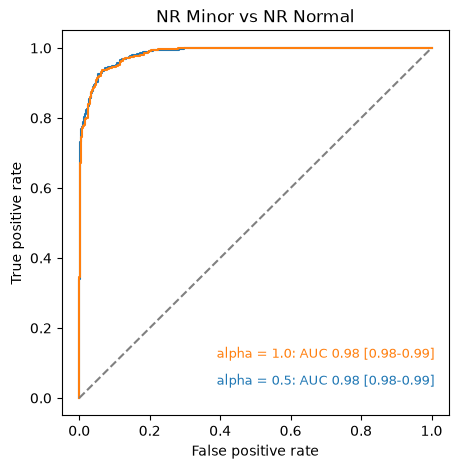

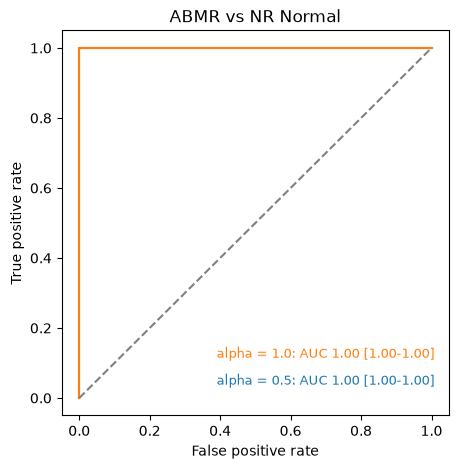

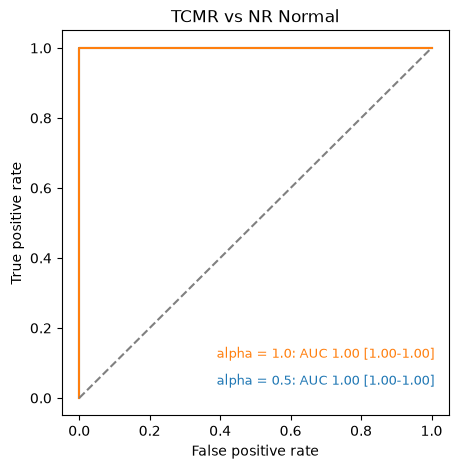

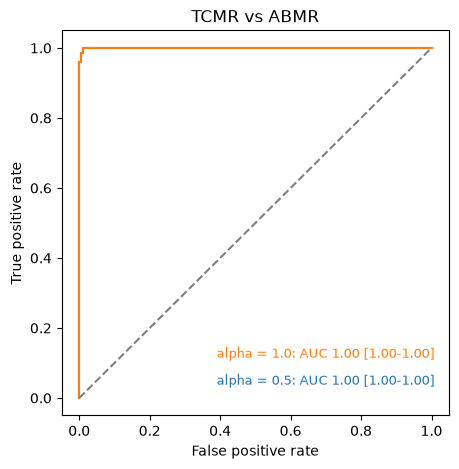

In [6]:
def boot_auc_ci(y, p, n_boot=2000, seed=SEED):
    """Bootstrap 95% CI for the AUC, like pROC::ci.auc(method = "bootstrap")."""
    rng = np.random.default_rng(seed)
    y, p = np.asarray(y), np.asarray(p)
    aucs = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y))          # resample samples with replacement
        if len(np.unique(y[i])) == 2:                # skip resamples with only one class
            aucs.append(roc_auc_score(y[i], p[i]))
    return np.percentile(aucs, [2.5, 97.5])

for g1, g2 in comparisons:
    name = f"{g2} vs {g1}"
    fig, ax = plt.subplots(figsize=(5, 5))

    for i, alpha in enumerate(alphas):
        prob = oof[(name, alpha)]                                   # averaged out-of-fold predictions
        y = (labels.loc[prob.index, group_col] == g2).astype(int)
        fpr, tpr, _ = roc_curve(y, prob)
        auc = roc_auc_score(y, prob)
        lo, hi = boot_auc_ci(y, prob)
        color = f"C{i}"
        ax.plot(fpr, tpr, color=color)
        ax.text(0.40, 0.08 + 0.07 * i, f"alpha = {alpha}: AUC {auc:.2f} [{lo:.2f}-{hi:.2f}]",
                color=color, transform=ax.transAxes, fontsize=9)

    ax.plot([0, 1], [0, 1], ls="--", color="grey")
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")
    ax.set_title(name)
    fig.savefig(f"../results/roc_{name.replace(' ', '_')}.png", dpi=150, bbox_inches="tight")